In [1]:
from keras.datasets import reuters

num_words = 10_000
(train_data, train_labels), (test_data, test_labels) = reuters.load_data(
    num_words=num_words
)

print(f"{train_data.shape}")
print(f"{train_labels.shape}")
print(f"{test_data.shape}")
print(f"{test_labels.shape}")

(8982,)
(8982,)
(2246,)
(2246,)


In [2]:
word_index = reuters.get_word_index()
reversed_word_index = {value: key for key, value in word_index.items()}
decoded_newswire_example = " ".join(
    [reversed_word_index.get(i - 3, "?") for i in train_data[0]]
)
decoded_newswire_example[:100]

'? ? ? said as a result of its december acquisition of space co it expects earnings per share in 1987'

In [3]:
import numpy as np


def multi_hot_encode(sequences, num_words):
    x = np.zeros(shape=(len(sequences), num_words), dtype="float32")
    for i, sequence in enumerate(sequences):
        x[i, sequence] = 1.0
    return x

In [4]:
x_train = multi_hot_encode(train_data, num_words)
x_test = multi_hot_encode(test_data, num_words)
y_train = multi_hot_encode(train_labels, num_words=46)
y_test = multi_hot_encode(test_labels, num_words=46)

print(f"{x_train.shape}")
print(f"{y_train.shape}")
print(f"{x_test.shape}")
print(f"{y_test.shape}")

(8982, 10000)
(8982, 46)
(2246, 10000)
(2246, 46)


In [5]:
import keras

keras.utils.set_random_seed(1)

model = keras.Sequential(
    [
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(64, activation="relu"),
        keras.layers.Dense(46, activation="softmax"),
    ]
)

top_3_accuracy = keras.metrics.TopKCategoricalAccuracy(k=3, name="top_3_accuracy")
model.compile(
    optimizer="adam",
    loss="categorical_crossentropy",
    metrics=["accuracy", top_3_accuracy],
)

history = model.fit(
    x_train,
    y_train,
    batch_size=512,
    epochs=20,
    validation_split=0.2,
)

Epoch 1/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.2475 - loss: 3.4892 - top_3_accuracy: 0.4976 - val_accuracy: 0.5982 - val_loss: 2.8655 - val_top_3_accuracy: 0.6900
Epoch 2/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6271 - loss: 2.3404 - top_3_accuracy: 0.7539 - val_accuracy: 0.6349 - val_loss: 1.8618 - val_top_3_accuracy: 0.7618
Epoch 3/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6899 - loss: 1.5170 - top_3_accuracy: 0.8024 - val_accuracy: 0.7134 - val_loss: 1.4055 - val_top_3_accuracy: 0.8052
Epoch 4/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7646 - loss: 1.1078 - top_3_accuracy: 0.8628 - val_accuracy: 0.7490 - val_loss: 1.1928 - val_top_3_accuracy: 0.8358
Epoch 5/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8231 - loss: 0.8590 - top_3_accuracy: 0.9083 - val_accuracy: 0.7730 - val_loss: 1.0823 - val_top_3_accuracy: 0.8653
Epoch 6/20
15/15 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.8647 - loss: 0.6724 - top_3_accuracy

In [6]:
history.history.keys()

dict_keys(['accuracy', 'loss', 'top_3_accuracy', 'val_accuracy', 'val_loss', 'val_top_3_accuracy'])

In [7]:
loss = history.history["loss"]
val_loss = history.history["val_loss"]
accuracy = history.history["accuracy"]
val_accuracy = history.history["val_accuracy"]
top_3_accuracy = history.history["top_3_accuracy"]
val_top_3_accuracy = history.history["val_top_3_accuracy"]
epochs = range(1, len(loss) + 1)


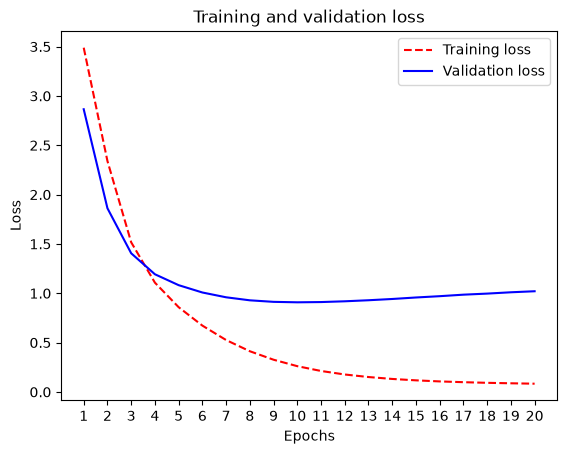

In [8]:
import matplotlib.pyplot as plt

plt.plot(epochs, loss, "r--", label="Training loss")
plt.plot(epochs, val_loss, "b", label="Validation loss")
plt.title("Training and validation loss")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Loss")
plt.legend()
plt.show()

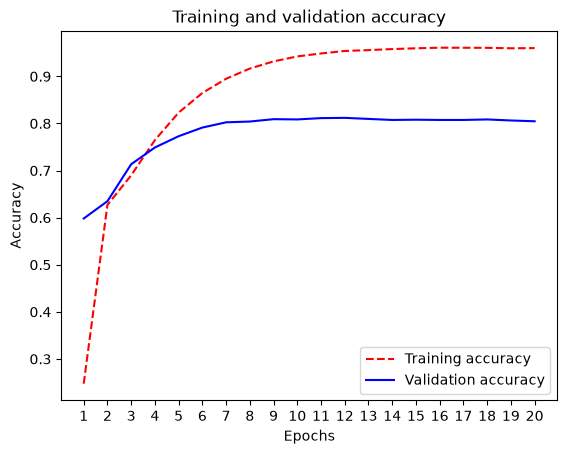

In [9]:
plt.clf()
acc = history.history["accuracy"]
val_acc = history.history["val_accuracy"]
plt.plot(epochs, acc, "r--", label="Training accuracy")
plt.plot(epochs, val_acc, "b", label="Validation accuracy")
plt.title("Training and validation accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Accuracy")
plt.legend()
plt.show()

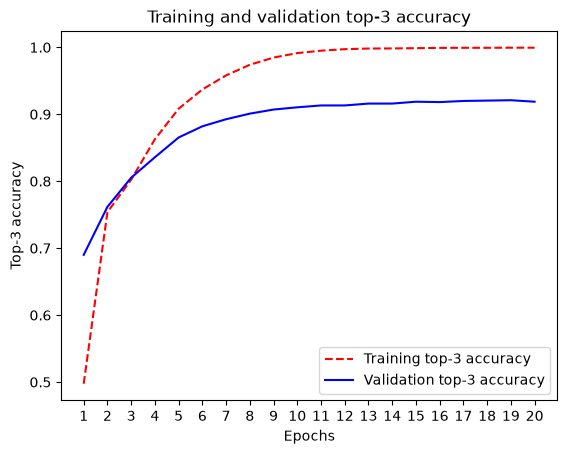

In [10]:
plt.clf()
acc = history.history["top_3_accuracy"]
val_acc = history.history["val_top_3_accuracy"]
plt.plot(epochs, acc, "r--", label="Training top-3 accuracy")
plt.plot(epochs, val_acc, "b", label="Validation top-3 accuracy")
plt.title("Training and validation top-3 accuracy")
plt.xlabel("Epochs")
plt.xticks(epochs)
plt.ylabel("Top-3 accuracy")
plt.legend()
plt.show()

In [11]:
results = model.evaluate(x_test, y_test)

71/71 ━━━━━━━━━━━━━━━━━━━━ 0s 439us/step - accuracy: 0.7961 - loss: 1.0911 - top_3_accuracy: 0.9052


In [12]:
import copy

# The "random" accuracy baseline
test_labels_copy = copy.copy(test_labels)
np.random.shuffle(test_labels_copy)
hits_array = np.array(test_labels == test_labels_copy)
hits_array.mean()

np.float64(0.19367764915405164)